In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load SMS Spam Collection dataset
df = pd.read_csv(
    "data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["Label", "Message"]
)

# Display first 5 records
df.head()

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Distribution of labels
print("\nLabel Distribution:")
print(df['Label'].value_counts())

Dataset Shape: (5572, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Label    5572 non-null   object
 1   Message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
Label      0
Message    0
dtype: int64

Duplicate Records: 403

Label Distribution:
Label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
# Remove exact duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Verify
print("Updated Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

print("\nUpdated Label Distribution:")
print(df['Label'].value_counts())

Updated Shape: (5169, 2)
Remaining Duplicates: 0

Updated Label Distribution:
Label
ham     4516
spam     653
Name: count, dtype: int64


count    5169.000000
mean       79.344554
std        58.437457
min         2.000000
25%        36.000000
50%        61.000000
75%       119.000000
max       910.000000
Name: Message_Length, dtype: float64

Average Message Length:
Label
ham      70.905890
spam    137.704441
Name: Message_Length, dtype: float64


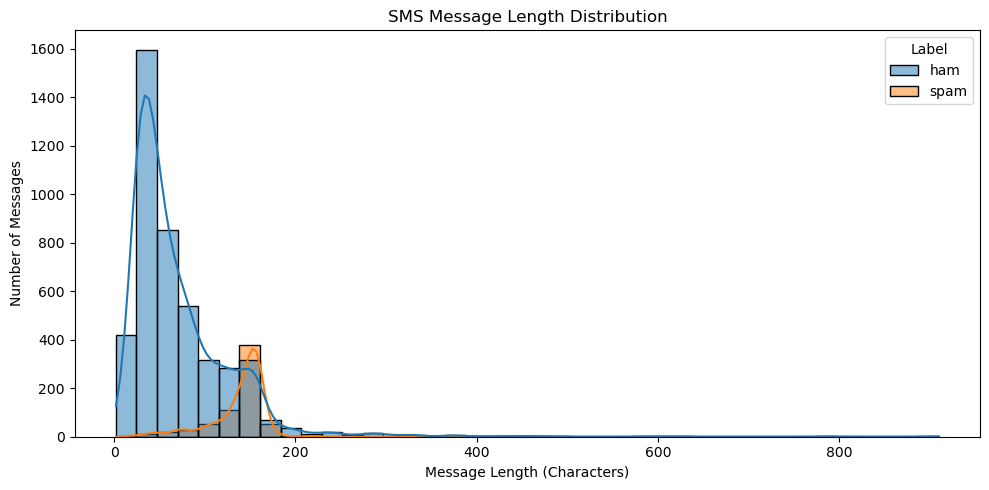

In [4]:
# Calculate message length
df['Message_Length'] = df['Message'].apply(len)

# Basic statistics
print(df['Message_Length'].describe())

# Compare message lengths by label
print("\nAverage Message Length:")
print(df.groupby('Label')['Message_Length'].mean())

# Visualize message lengths
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Message_Length',
    hue='Label',
    bins=40,
    kde=True
)

plt.title('SMS Message Length Distribution')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Number of Messages')

plt.tight_layout()
plt.show()

### Message Length Analysis

The dataset contains 5,169 messages with an average length
of 79.34 characters and a median length of 61 characters.

The average Ham message length is 70.91 characters, while
the average Spam message length is 137.70 characters.

Spam messages are considerably longer on average than
legitimate messages. The maximum message length is
910 characters.

**Key Takeaway:** Message length may provide useful
information for spam classification, but text content
must also be considered.

In [5]:
# Display sample spam messages
print("SPAM MESSAGES:\n")

for message in df[df['Label'] == 'spam']['Message'].head(5):
    print("-", message)

print("\nHAM MESSAGES:\n")

for message in df[df['Label'] == 'ham']['Message'].head(5):
    print("-", message)

SPAM MESSAGES:

- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
- SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info

HAM MESSAGES:

- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then say...
- Nah 

In [6]:
import nltk

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully.")

NLTK resources downloaded successfully.


[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


In [7]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("Total English stopwords:", len(stop_words))
print("Sample stopwords:", list(stop_words)[:20])

Total English stopwords: 198
Sample stopwords: ['about', 'those', 'mightn', "shan't", "i'd", 'through', 'don', 'few', 'hadn', 'they', 'be', 'doesn', 'how', 'after', 'our', 'over', 'than', 'because', 'out', 'such']


In [8]:
sample_message = df['Message'].iloc[0]

# Convert to lowercase
lower_text = sample_message.lower()

# Split into individual words
tokens = word_tokenize(lower_text)

# Remove stopwords
filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

print("Original Message:\n", sample_message)
print("\nTokens:\n", tokens)
print("\nAfter Stopword Removal:\n", filtered_tokens)

Original Message:
 Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Tokens:
 ['go', 'until', 'jurong', 'point', ',', 'crazy', '..', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', '...', 'cine', 'there', 'got', 'amore', 'wat', '...']

After Stopword Removal:
 ['go', 'jurong', 'point', ',', 'crazy', '..', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', '...', 'cine', 'got', 'amore', 'wat', '...']


In [9]:
# Keep important negation words
important_words = {'no', 'not', 'nor', 'never'}

custom_stop_words = stop_words - important_words

print("Original stopwords:", len(stop_words))
print("Custom stopwords:", len(custom_stop_words))

print("\nAre negation words preserved?")
for word in important_words:
    print(word, ":", word not in custom_stop_words)

Original stopwords: 198
Custom stopwords: 195

Are negation words preserved?
no : True
not : True
nor : True
never : True


In [10]:
X = df['Message']
y = df['Label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (5169,)
Target shape: (5169,)

Target distribution:
Label
ham     4516
spam     653
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 4135
Testing samples: 1034

Training label distribution:
Label
ham     3613
spam     522
Name: count, dtype: int64

Testing label distribution:
Label
ham     903
spam    131
Name: count, dtype: int64


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words=list(custom_stop_words),
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Total vocabulary words/features:", len(tfidf.vocabulary_))

Training TF-IDF shape: (4135, 33863)
Testing TF-IDF shape: (1034, 33863)
Total vocabulary words/features: 33863


In [13]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes training completed!")

Multinomial Naive Bayes training completed!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes Evaluation\n")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, pos_label='spam'))
print("Recall:", recall_score(y_test, y_pred_nb, pos_label='spam'))
print("F1-Score:", f1_score(y_test, y_pred_nb, pos_label='spam'))

print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Evaluation

Accuracy: 0.9545454545454546
Precision: 1.0
Recall: 0.6412213740458015
F1-Score: 0.7813953488372093

Detailed Classification Report:

              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.64      0.78       131

    accuracy                           0.95      1034
   macro avg       0.98      0.82      0.88      1034
weighted avg       0.96      0.95      0.95      1034



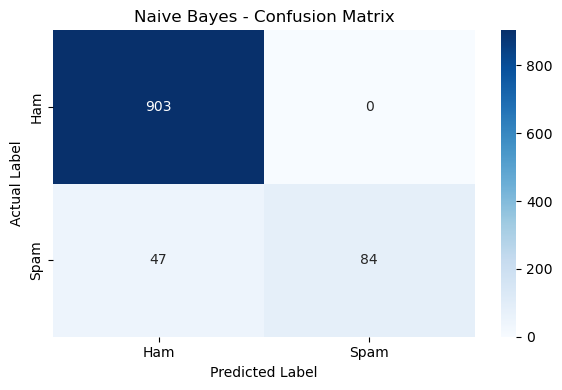

Confusion Matrix:
 [[903   0]
 [ 47  84]]


In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=['ham', 'spam']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm_nb)

In [16]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [17]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression Evaluation\n")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, pos_label='spam'))
print("Recall:", recall_score(y_test, y_pred_lr, pos_label='spam'))
print("F1-Score:", f1_score(y_test, y_pred_lr, pos_label='spam'))

print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation

Accuracy: 0.9439071566731141
Precision: 0.9294117647058824
Recall: 0.6030534351145038
F1-Score: 0.7314814814814815

Detailed Classification Report:

              precision    recall  f1-score   support

         ham       0.95      0.99      0.97       903
        spam       0.93      0.60      0.73       131

    accuracy                           0.94      1034
   macro avg       0.94      0.80      0.85      1034
weighted avg       0.94      0.94      0.94      1034



                 Model  Accuracy  Precision  Recall  F1-Score
0          Naive Bayes    0.9545     1.0000  0.6412    0.7814
1  Logistic Regression    0.9439     0.9294  0.6031    0.7315


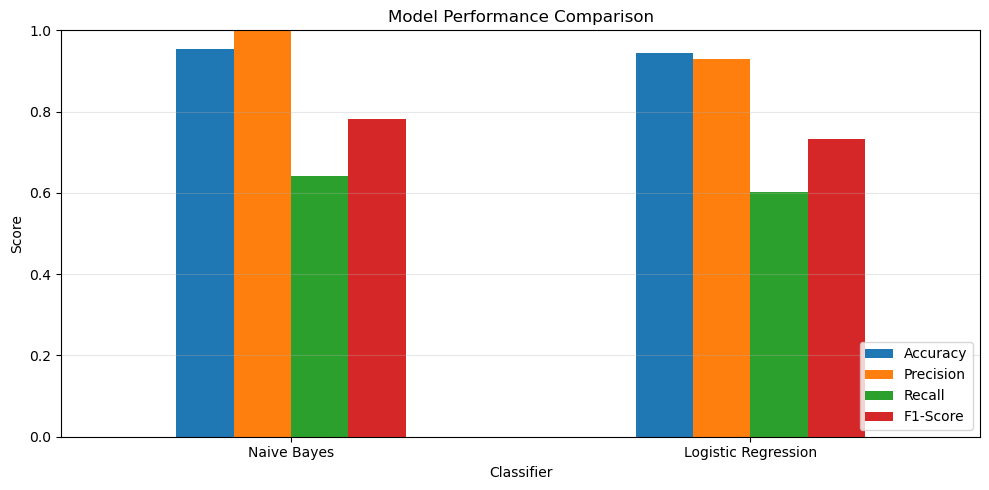

In [18]:
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],
    'Precision': [
        precision_score(y_test, y_pred_nb, pos_label='spam'),
        precision_score(y_test, y_pred_lr, pos_label='spam')
    ],
    'Recall': [
        recall_score(y_test, y_pred_nb, pos_label='spam'),
        recall_score(y_test, y_pred_lr, pos_label='spam')
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_nb, pos_label='spam'),
        f1_score(y_test, y_pred_lr, pos_label='spam')
    ]
})

print(results.round(4))

results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Classifier')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Get prediction probabilities for spam
spam_index = list(nb_model.classes_).index('spam')

nb_probabilities = nb_model.predict_proba(X_test_tfidf)[:, spam_index]

print("First 10 spam probabilities:")
print(nb_probabilities[:10])

print("\nModel classes:", nb_model.classes_)

First 10 spam probabilities:
[0.00052521 0.01995992 0.01209942 0.01770359 0.01337259 0.01185449
 0.00849141 0.00118922 0.01513789 0.00855588]

Model classes: ['ham' 'spam']


In [20]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Fit a fresh vectorizer only on subtraining data
val_tfidf = TfidfVectorizer(
    stop_words=list(custom_stop_words),
    ngram_range=(1, 2)
)

X_subtrain_tfidf = val_tfidf.fit_transform(X_subtrain)
X_val_tfidf = val_tfidf.transform(X_val)

# Train a validation Naive Bayes model
nb_val_model = MultinomialNB()
nb_val_model.fit(X_subtrain_tfidf, y_subtrain)

print("Subtraining samples:", len(X_subtrain))
print("Validation samples:", len(X_val))
print("Validation preparation completed!")

Subtraining samples: 3308
Validation samples: 827
Validation preparation completed!


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get spam probabilities from validation data
spam_index = list(nb_val_model.classes_).index('spam')

val_probabilities = nb_val_model.predict_proba(X_val_tfidf)[:, spam_index]

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds:
    predictions = np.where(
        val_probabilities >= threshold,
        'spam',
        'ham'
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, predictions, pos_label='spam'),
        'Recall': recall_score(y_val, predictions, pos_label='spam'),
        'F1-Score': f1_score(y_val, predictions, pos_label='spam')
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Precision  Recall  F1-Score
0        0.2     0.9747  0.7404    0.8415
1        0.3     0.9855  0.6538    0.7861
2        0.4     1.0000  0.5769    0.7317
3        0.5     1.0000  0.4904    0.6581
4        0.6     1.0000  0.3942    0.5655
5        0.7     1.0000  0.3462    0.5143
6        0.8     1.0000  0.1923    0.3226


In [22]:
# Final TF-IDF vectorizer
final_tfidf = TfidfVectorizer(
    stop_words=list(custom_stop_words),
    ngram_range=(1, 2)
)

X_train_final = final_tfidf.fit_transform(X_train)

# Final Naive Bayes model
final_nb_model = MultinomialNB()
final_nb_model.fit(X_train_final, y_train)

print("Final Naive Bayes model trained!")
print("Training samples:", X_train_final.shape[0])
print("Vocabulary size:", len(final_tfidf.vocabulary_))
print("Selected threshold: 0.2")

Final Naive Bayes model trained!
Training samples: 4135
Vocabulary size: 33863
Selected threshold: 0.2


In [23]:
# Transform test messages using the final vectorizer
X_test_final = final_tfidf.transform(X_test)

# Get spam probabilities
spam_index = list(final_nb_model.classes_).index('spam')

final_probabilities = final_nb_model.predict_proba(
    X_test_final
)[:, spam_index]

# Apply selected threshold
final_predictions = np.where(
    final_probabilities >= 0.2,
    'spam',
    'ham'
)

# Evaluate
print("Final Model Evaluation\n")

print("Accuracy:", accuracy_score(y_test, final_predictions))
print("Precision:", precision_score(y_test, final_predictions, pos_label='spam'))
print("Recall:", recall_score(y_test, final_predictions, pos_label='spam'))
print("F1-Score:", f1_score(y_test, final_predictions, pos_label='spam'))

print("\nClassification Report:\n")
print(classification_report(y_test, final_predictions))

Final Model Evaluation

Accuracy: 0.9729206963249516
Precision: 0.9813084112149533
Recall: 0.8015267175572519
F1-Score: 0.8823529411764706

Classification Report:

              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       0.98      0.80      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.90      0.93      1034
weighted avg       0.97      0.97      0.97      1034



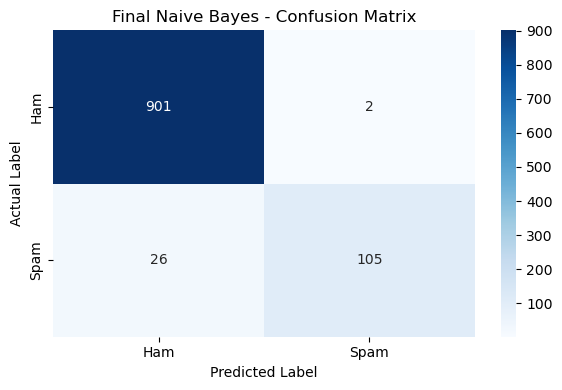

Final Confusion Matrix:
 [[901   2]
 [ 26 105]]


In [24]:
cm_final = confusion_matrix(
    y_test,
    final_predictions,
    labels=['ham', 'spam']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_final,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Final Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Final Confusion Matrix:\n", cm_final)

In [25]:
def predict_message(message):

    # Convert message into TF-IDF features
    message_tfidf = final_tfidf.transform([message])

    # Get spam probability
    spam_index = list(final_nb_model.classes_).index('spam')

    spam_probability = final_nb_model.predict_proba(
        message_tfidf
    )[0][spam_index]

    # Apply selected threshold
    prediction = (
        'spam' if spam_probability >= 0.2 else 'ham'
    )

    print("Message:", message)
    print("Prediction:", prediction.upper())
    print(f"Spam Probability: {spam_probability:.2%}")


print("Prediction function created successfully!")

Prediction function created successfully!


In [26]:
# Test 1: Normal message
predict_message("Hey, are we meeting tomorrow at university?")

print("\n" + "-" * 50 + "\n")

# Test 2: Promotional spam
predict_message("Congratulations! You have won a free prize. Call now to claim your reward!")

print("\n" + "-" * 50 + "\n")

# Test 3: Suspicious offer
predict_message("URGENT! You have won $1000 cash. Click here to claim your free reward!")

Message: Hey, are we meeting tomorrow at university?
Prediction: HAM
Spam Probability: 0.99%

--------------------------------------------------

Message: Congratulations! You have won a free prize. Call now to claim your reward!
Prediction: SPAM
Spam Probability: 79.56%

--------------------------------------------------

Message: URGENT! You have won $1000 cash. Click here to claim your free reward!
Prediction: SPAM
Spam Probability: 85.69%


In [32]:
while True:
    message = input("\nEnter a message (or type 'exit' to stop): ")

    if message.lower() == 'exit':
        print("Prediction session ended.")
        break

    predict_message(message)


Enter a message (or type 'exit' to stop):  you have won free prize


Message: you have won free prize
Prediction: SPAM
Spam Probability: 63.17%



Enter a message (or type 'exit' to stop):  hi this is me mohsin


Message: hi this is me mohsin
Prediction: HAM
Spam Probability: 2.56%



Enter a message (or type 'exit' to stop):  exit


Prediction session ended.


In [28]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_artifact = {
    "model": final_nb_model,
    "vectorizer": final_tfidf,
    "threshold": 0.2
}

joblib.dump(model_artifact, "models/spam_classifier.joblib")

print("Model saved successfully!")

Model saved successfully!


In [29]:
import joblib

loaded_artifact = joblib.load("models/spam_classifier.joblib")

loaded_model = loaded_artifact["model"]
loaded_vectorizer = loaded_artifact["vectorizer"]
loaded_threshold = loaded_artifact["threshold"]

test_message = ["Congratulations! You have won a free prize. Call now!"]

message_features = loaded_vectorizer.transform(test_message)

spam_index = list(loaded_model.classes_).index("spam")

spam_probability = loaded_model.predict_proba(message_features)[0][spam_index]

prediction = "spam" if spam_probability >= loaded_threshold else "ham"

print("Prediction:", prediction.upper())
print(f"Spam Probability: {spam_probability:.2%}")
print("Loaded threshold:", loaded_threshold)

Prediction: SPAM
Spam Probability: 65.71%
Loaded threshold: 0.2
